# Issue #205 — M×3 value matrix and joint N7 payoff calibration

This thin notebook verifies the immutable package, renders the matched baseline comparison, and exposes the decision. Core identity, calibration, settlement, fallback and plotting logic lives in `src/unified_value/joint_n7.py`. The analysis uses one deterministic first-seven panel per issue and exhaustively scores all $3^7$ outcome identities; it performs no ticket sampling or portfolio optimization.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(path for path in candidates if (path / 'src').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from unified_value.joint_n7 import verify
PACKAGE = ROOT / 'results' / 'issue-205'
receipt = verify(PACKAGE)
receipt

{'status': 'PASS',
 'files': 18,
 'manifest_sha256': 'c4d39ba0223abea7be0e71b098cc86cc2006f6495787c1ee31fba4564e609fa9',
 'control_rows_verified': 205251}

In [2]:
decision = json.loads((PACKAGE / 'decision.json').read_text())
metrics = pd.read_csv(PACKAGE / 'metrics.csv')
display(pd.DataFrame([decision]))
display(metrics.sort_values(['split', 'joint_log_loss']))

,covered_issues,cv_dependence_improves_both_controls,disposition,experimental_allowed_use,experimental_confirmation_dependency,experimental_probability_column,experimental_promoted,experimental_source_grade,fallback_issues,inherited_scorer,locked_dependence_improves_both_controls,locked_market_joint_log_loss,locked_selected_joint_log_loss,primary_metric,safe_control_columns_for_206,safe_control_probability_column,safe_control_probability_source,safe_control_source_grade,selected_on_cv,version
0,75,False,INHERIT_EXACT_MARKET_BASELINE,ablation_feature_only,#210,experimental_probability,False,RETROSPECTIVE_PROXY_METHOD_CORRECTION,0,MARKET_INDEPENDENCE,False,8.175457,8.111346,joint_log_loss,"[control_probability, control_probability_sour...",control_probability,MARKET_ONLY,FROZEN_SAFE_BASELINE,SIMPLE_REGIME_DEPENDENCE,bj205-joint-n7-value-matrix-v2


,split,model,issues,ticket_candidates,realized_hits,joint_log_loss,joint_brier,mean_realized_configuration_probability,payout_mae,mean_predicted_net,mean_realized_net,model_covered_issues,fallback_issues,matched_lift_joint_log_loss_vs_market,matched_lift_joint_brier_vs_market,matched_lift_payout_mae_vs_market
2,CV_2022,SIMPLE_REGIME_DEPENDENCE,58,126846,58,8.286085,1.000908,0.000610,1.501181,-0.300585,-0.197588,58,0,NaN,NaN,NaN
1,CV_2022,MODEL_INDEPENDENCE,58,126846,58,8.294819,1.001146,0.000620,1.486974,-0.314804,-0.197588,58,0,NaN,NaN,NaN
0,CV_2022,MARKET_INDEPENDENCE,58,126846,58,8.340984,1.000614,0.000532,1.612415,-0.189365,-0.197588,58,0,NaN,NaN,NaN
3,CV_2022,LATENT_SET_DEPENDENCE,58,126846,58,8.679234,1.003506,0.000763,1.358205,-0.443539,-0.197588,58,0,NaN,NaN,NaN
5,CV_2023,MODEL_INDEPENDENCE,55,120285,55,7.920298,1.000779,0.000819,1.327360,-0.328255,-0.343625,55,0,NaN,NaN,NaN
6,CV_2023,SIMPLE_REGIME_DEPENDENCE,55,120285,55,7.929448,1.000602,0.000784,1.341896,-0.313742,-0.343625,55,0,NaN,NaN,NaN
7,CV_2023,LATENT_SET_DEPENDENCE,55,120285,55,7.965281,1.001485,0.000929,1.211400,-0.444192,-0.343625,55,0,NaN,NaN,NaN
4,CV_2023,MARKET_INDEPENDENCE,55,120285,55,8.085904,1.000496,0.000685,1.443994,-0.211684,-0.343625,55,0,NaN,NaN,NaN
10,LOCKED_TEST,SIMPLE_REGIME_DEPENDENCE,75,164025,75,8.111346,1.000825,0.000590,1.423181,-0.313440,-0.262749,75,0,-0.064111,0.000176,-0.091894
9,LOCKED_TEST,MODEL_INDEPENDENCE,75,164025,75,8.114877,1.001046,0.000598,1.411927,-0.324687,-0.262749,75,0,-0.060579,0.000397,-0.103148


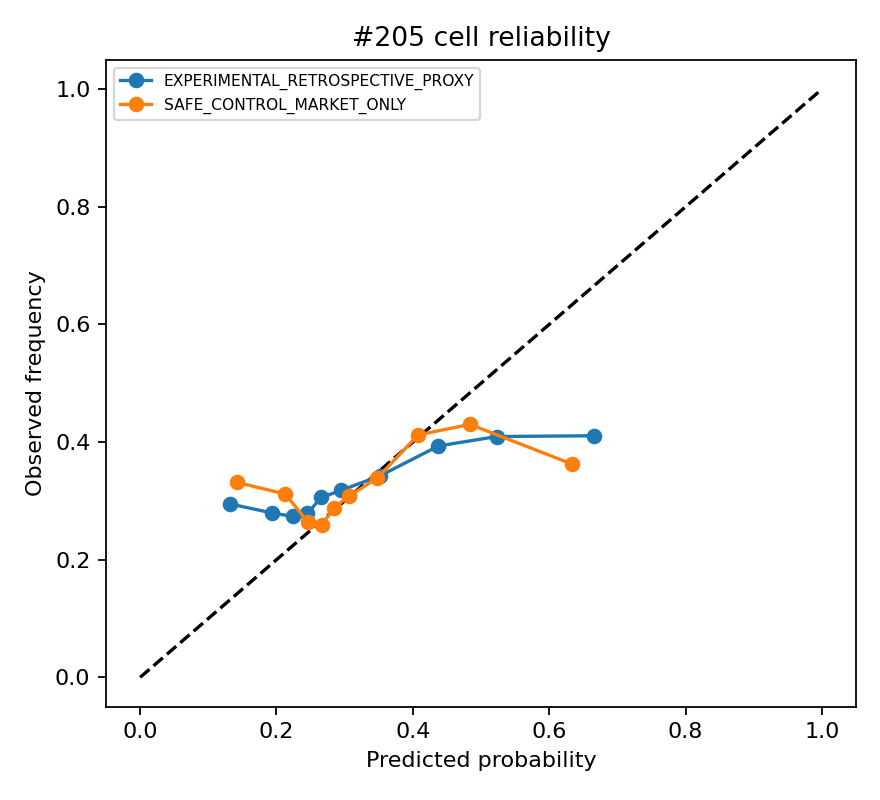

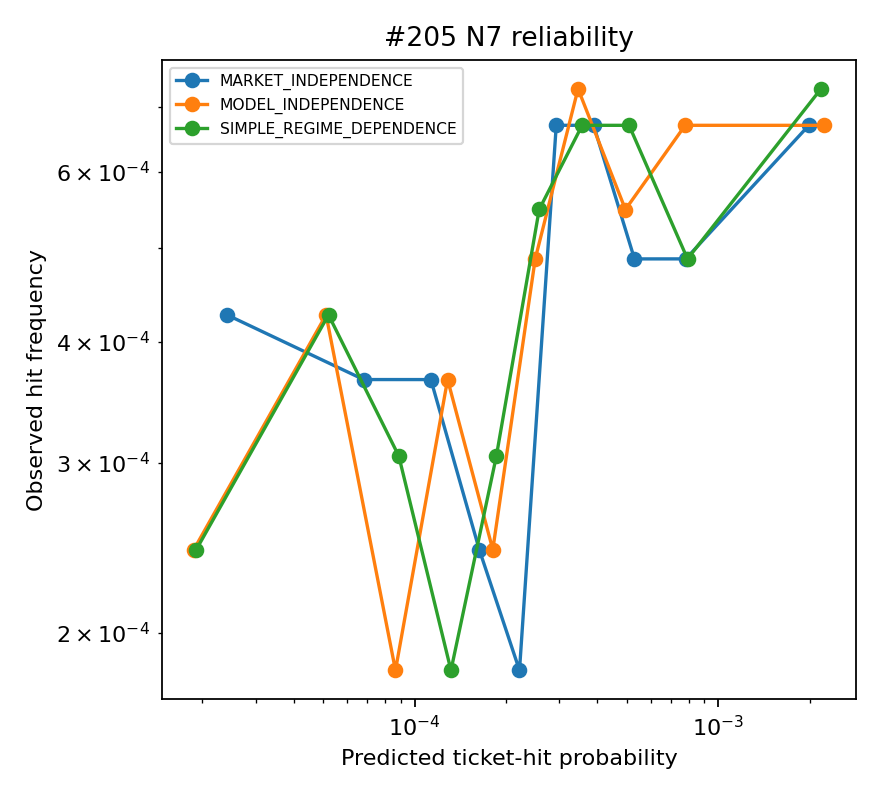

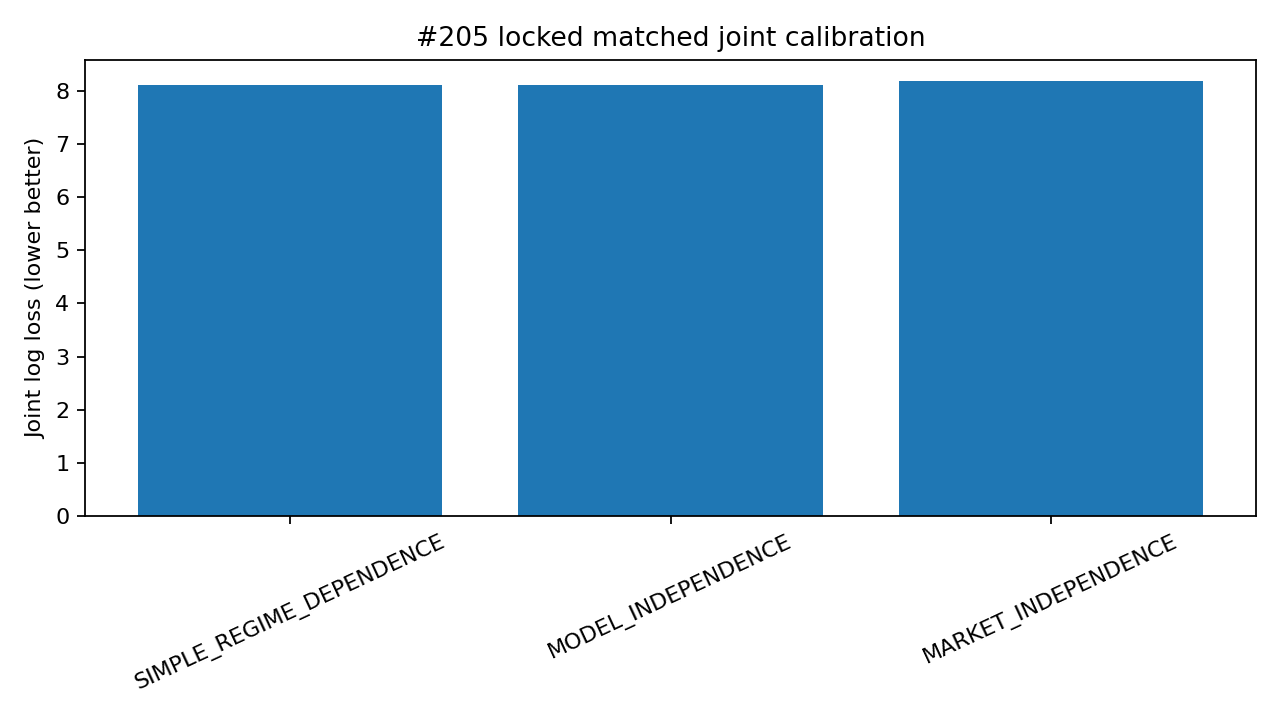

In [3]:
display(Image(filename=str(PACKAGE / 'cell_reliability.png')))
display(Image(filename=str(PACKAGE / 'ticket_reliability.png')))
display(Image(filename=str(PACKAGE / 'locked_joint_log_loss.png')))

## Interpretation and PI handoff

The controlling disposition is in `results/issue-205/decision.json`; the notebook does not alter it. The #206 safe lane is `control_probability` (`MARKET_ONLY`, `FROZEN_SAFE_BASELINE`, promoted) with the frozen pre-event SP head and `MARKET_INDEPENDENCE`. Every logistic-residual-derived probability, residual, gross/net and displayed utility is named `experimental_*`, graded `RETROSPECTIVE_PROXY_METHOD_CORRECTION`, `promoted=false`, and depends on #210 confirmation.

The challenger is promising retrospective evidence but did not advance: it was slightly worse than model independence on chronological CV and worse than market on locked Brier, despite improved locked log loss and payout MAE. Unsupported joint regions fall back to the exact market-independence vector; fewer-than-seven regions are `NO_BET_LT7`. See `DECISION_REPORT.md` for the complete PI handoff.